In [1]:
import os
import torch
import random
import matplotlib.pyplot as plt
F = torch.nn.functional
torch.set_num_threads(1)

In [2]:
with open("names.txt", "r+") as file:
    contents = file.read()

split_lines = contents.splitlines()
random.shuffle(split_lines)
char_set = sorted(set(''.join(split_lines)))


In [7]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), requires_grad=True, generator=g)
W1 = torch.randn((30, 200), requires_grad=True, generator=g)
B1 = torch.randn((200,), requires_grad=True, generator=g)
W2 = torch.randn((200, 27), requires_grad=True, generator=g)
B2 = torch.randn((27,), requires_grad=True, generator=g)
block_size = 3

parameters = list([C, W1, B1, W2, B2])

ch2i = {}
i2ch = {}
ch2i['.'] = 0
i2ch[0] = '.'

for i, v in enumerate(char_set):
    ch2i[v] = i + 1
    i2ch[i + 1] = v

In [4]:
def convert_names(names):
    converted = []
    X = []
    Y = []
    for v in names:
        added = list(v)
        context = ['.'] * block_size
        for target in added + ['.']:
            nums = []
            for c in context:
                nums.append(ch2i[c])
            X.append(nums)
            Y.append(ch2i[target])
            converted.append((context, target))
            context = context[1:] + [target]
    tx = torch.tensor(X)
    ty = torch.tensor(Y)
    return tx, ty

In [5]:
train_set = int(0.8 * len(split_lines))
dev_set = train_set + int(0.1 * len(split_lines))
test_set = dev_set + int(0.1 * len(split_lines))


Xtr, Ytr = convert_names(split_lines[0:train_set])
Xdev, Ydev = convert_names(split_lines[train_set:dev_set])
Xtest, Ytest = convert_names(split_lines[dev_set:test_set])

dim_N_X = []

In [9]:

# for x in tx[3:4]:
#     tmp = []
#     for i in x:
#         tmp.append(C[i])
#     conc = torch.cat(tmp)
#     dim_N_X.append(conc)

# emb = C[tx]
# dim_N_X = torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], dim=1)

#最终写法，当前最优解
# dim_N_X = C[tx].view(-1, 6)

# print(dim_N_X[:3])

# lre = torch.linspace(-3, 0, 1000)
# lrs = 10 ** lre
lossi = []
for i in range(100000):
    batch_indices = torch.randint(0, len(Xtr), (32,))
    batch_x = Xtr[batch_indices]
    batch_y = Ytr[batch_indices]
    dim_N_X = C[batch_x].view(-1, 30)
    hidden = torch.tanh(dim_N_X @ W1 + B1)
    logits = hidden @ W2 + B2
    loss = F.cross_entropy(logits, batch_y)
    lossi.append(loss.item())
    for p in parameters:
        p.grad = None
    loss.backward()
    with torch.no_grad():
        for p in parameters:
            # p.data -= lrs[i] * p.grad
            p.data -= 0.01 * p.grad

In [10]:
dim_N_X = C[Xtr].view(-1, 30)
hidden = torch.tanh(dim_N_X @ W1 + B1)
logits = hidden @ W2 + B2
loss2 = F.cross_entropy(logits, Ytr)
print(loss2)

dim_N_X_dev = C[Xdev].view(-1, 30)
hidden_dev = torch.tanh(dim_N_X_dev @ W1 + B1)
logits_dev = hidden_dev @ W2 + B2
loss_dev = F.cross_entropy(logits_dev, Ydev)
print(loss_dev)

tensor(2.0780, grad_fn=<NllLossBackward0>)
tensor(2.1282, grad_fn=<NllLossBackward0>)


In [20]:
def generate_name():
    final_pred = ''
    context = [0, 0 ,0]
    while True:
        ctx_tensor = torch.tensor(context)
        with torch.no_grad():
            dim_N_X = C[ctx_tensor].view(1, -1)
            hidden = torch.tanh(dim_N_X @ W1 + B1)
            logits = hidden @ W2 + B2
            probs = F.softmax(logits, dim=1)
            index = torch.multinomial(probs, num_samples=1, replacement=True, generator=g)
        if index.item() == 0:
            break
        ch = i2ch[index.item()]
        final_pred += ch
        context = context[1:] + [index.item()]
    return final_pred

In [21]:
for _ in range(20):
    print(generate_name())

abyazmy
eludi
szayzerina
nick
rowerleserrie
rosellianr
cath
cetri
ana
lenix
keiana
amarquana
apo
ividhith
shyofiqhylanyleeonla
kalij
zammita
tavguel
talestell
sidena


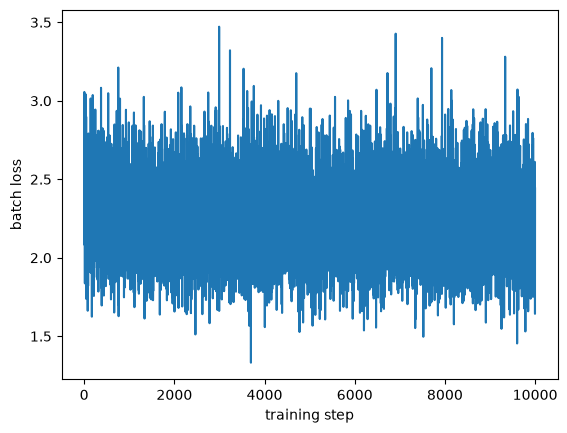

In [25]:
plt.plot(lossi)
plt.xlabel("training step")
plt.ylabel("batch loss")
plt.show()